Part 2:Logistic Regression from Scratch - Predicting Book Bestsellers

Objective:To build a logistic regression model from scratch using NumPy to predict whether a book will be a bestseller based on its metadata.
    
Analysis Plan
1.  Dataset Justification:We use the Google Books 15K dataset. As shown in the dataset documentation, 94% of the books lack ratings. We will filter the dataset to only include books with a recorded `ratings_count` to create a valid binary target (`is_bestseller`).
2.  EDA: Load data with PySpark, clean missing values, and visualise page count and ratings against bestseller status.
3.  Feature Selection:Select `page_count`, `average_rating`, and top categories/publishers. Standardise features.
4.  Train Model:Implement Sigmoid, Cost Function, and Gradient Descent from scratch.
5.  Evaluate & Retrain:Evaluate Model 1. If overfitting occurs, retrain with L2 Regularization (Model 2) and compare metrics.

Environment Setup
Apache Spark requires specific Java and Hadoop configurations on Windows. This cell sets the `JAVA_HOME` and `HADOOP_HOME` environment variables to ensure the PySpark session initializes correctly without crashing (Apache Spark, 2024).

In [1]:
import os
os.environ['JAVA_HOME'] = r"C:\Program Files\Eclipse Adoptium\jdk-17.0.20.101-hotspot"

# 2. Add Java 17 to the PATH so Spark uses it instead of Java 25
os.environ['PATH'] = os.environ['JAVA_HOME'] + r"\bin;" + os.environ['PATH']

#Set Hadoop home
os.environ['HADOOP_HOME'] = r"C:\hadoop"
os.environ['PATH'] = os.environ['HADOOP_HOME'] + r"\bin;" + os.environ['PATH']

#Now import PySpark
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Initialize Spark
print("Starting Spark...")
spark = SparkSession.builder.appName("BookBestsellerAnalysis").getOrCreate()
print("Spark Session Initialized successfully!")

Starting Spark...
Spark Session Initialized successfully!


Data Loading and Cleaning
We load the dataset using PySpark to demonstrate big data handling. However, because the raw CSV contains unescaped commas in the book descriptions which will cause the columns to misalign, we immediately transfer the data to a Pandas Data frame. Pandas is designed to help users explore, clean and process tabular data (pandas, 2024). We use Pandas to turn bad text into nulls and filter out books with a `ratings_count` of 0.

In [2]:
import pandas as pd
from pyspark.sql.functions import col

#Define File Path
file_path = r"C:\Users\bless\Pictures\a2\Book dataset\google_books_dataset.csv"


df_spark = spark.read.csv(file_path, header=True, inferSchema=True)

#Shift to Pandas to fix the broken CSV columns
print("Transferring to Pandas to fix column misalignment")
df_pandas = pd.read_csv(file_path)

#Force the columns to be numeric
# 'coerce' turns any bad text (like descriptions) into NaN (Null)
df_pandas['ratings_count'] = pd.to_numeric(df_pandas['ratings_count'], errors='coerce')
df_pandas['page_count'] = pd.to_numeric(df_pandas['page_count'], errors='coerce')
df_pandas['average_rating'] = pd.to_numeric(df_pandas['average_rating'], errors='coerce')

#Drop rows where critical data is missing or 0
df_pandas = df_pandas.dropna(subset=['page_count', 'average_rating', 'ratings_count', 'categories'])
df_pandas = df_pandas[df_pandas['ratings_count'] > 0]

print(f"Cleaned Data Count: {len(df_pandas)} records.")

#Verify if it workef
if len(df_pandas) > 0:
    print("\nSample of cleaned data:")
    display(df_pandas[['title', 'page_count', 'average_rating', 'ratings_count']].head())
else:
    print("\nStill 0 records. The CSV might be fundamentally broken or not have ratings.")

Transferring to Pandas to fix column misalignment
Cleaned Data Count: 815 records.

Sample of cleaned data:


,title,page_count,average_rating,ratings_count
13,Readers' Guide to Periodical Literature,1478.0,4.0,1
130,Searching for Faith (A Carissa Jones Crime Thr...,193.0,2.0,1
151,The Year's Best Science Fiction: Twenty-Eighth...,767.0,3.0,1
153,The Year's Best Science Fiction: Twenty-Fifth ...,706.0,4.0,6
194,Handbook of Russian Literature,584.0,5.0,1


Exploratory Data Analysis
We define our target variable, `is_bestseller`. A book is classified as a bestseller if its rating count is in the top 25th percentile of our cleaned data. We then visualise the distribution of page counts and average ratings to see if there are obvious visual patterns between bestsellers and non bestsellers.

Bestseller Threshold (75th percentile): 3 ratings.

Target Variable Counts:
is_bestseller
0    604
1    211
Name: count, dtype: int64


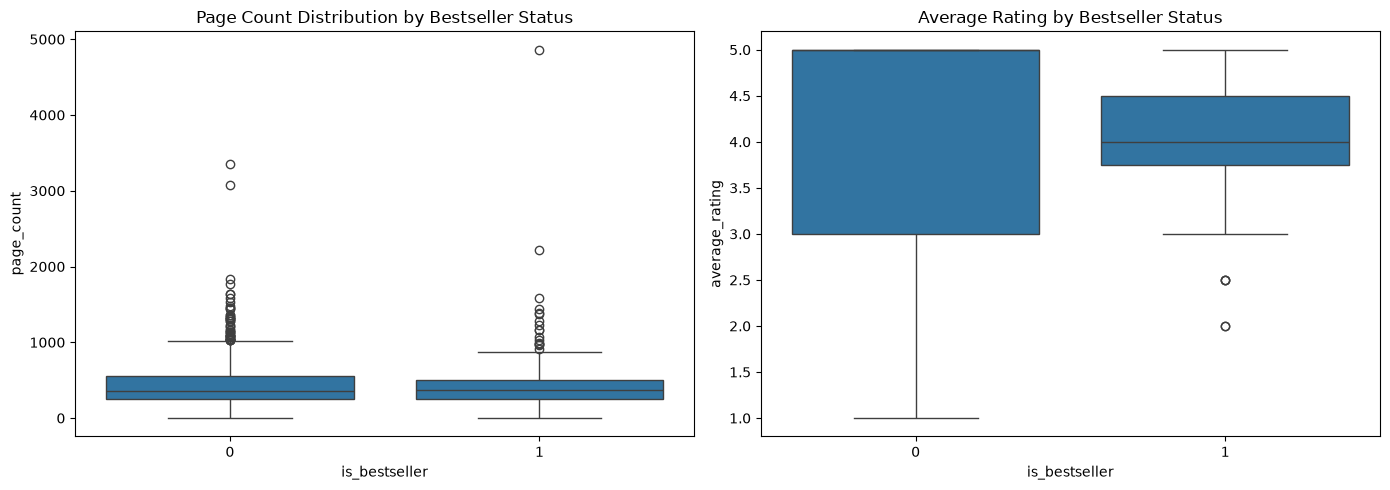

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

#Create Target Variable (Bestseller)
threshold = int(df_pandas['ratings_count'].quantile(0.75)) 
print(f"Bestseller Threshold (75th percentile): {threshold} ratings.")

df_pandas['is_bestseller'] = (df_pandas['ratings_count'] >= threshold).astype(int)

print("\nTarget Variable Counts:")
print(df_pandas['is_bestseller'].value_counts())

# 5. EDA Visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Page Count vs Bestseller
sns.boxplot(x='is_bestseller', y='page_count', data=df_pandas, ax=axes[0])
axes[0].set_title('Page Count Distribution by Bestseller Status')
# Note: We removed set_xticklabels to stop the warning. Let matplotlib handle the 0 and 1.

# Plot 2: Average Rating vs Bestseller
sns.boxplot(x='is_bestseller', y='average_rating', data=df_pandas, ax=axes[1])
axes[1].set_title('Average Rating by Bestseller Status')

plt.tight_layout()
plt.show()

Feature Selection and Engineering
We select numerical features (`page_count`, `average_rating`) and create dummy variables for the top 10 categories and publishers. Finally, we apply Z-score standardisation to the features. This is crucial for Gradient Descent, as it ensures the algorithm converges efficiently without features with larger scales taking over the gradient updates.

In [4]:
#Feature Selection
top_categories = df_pandas['categories'].value_counts().nlargest(10).index
top_publishers = df_pandas['publisher'].value_counts().nlargest(10).index

df_pandas['cat_group'] = df_pandas['categories'].apply(lambda x: x if x in top_categories else 'Other')
df_pandas['pub_group'] = df_pandas['publisher'].apply(lambda x: x if x in top_publishers else 'Other')

df_features = pd.get_dummies(df_pandas, columns=['cat_group', 'pub_group'], drop_first=True)

features = ['page_count', 'average_rating'] + [c for c in df_features.columns if c.startswith('cat_group_') or c.startswith('pub_group_')]
X = df_features[features].astype(float)
y = df_features['is_bestseller'].astype(float)

#Normalize Features
X_mean = X.mean()
X_std = X.std()
X_normalized = (X - X_mean) / X_std
X_normalized = X_normalized.fillna(0)

#Convert to NumPy arrays for the from-scratch math
X_array = X_normalized.values
y_array = y.values.reshape(-1, 1)
print(f"Final Feature Matrix Shape: {X_array.shape}")
print("Data is ready for the from-scratch model.")

Final Feature Matrix Shape: (815, 22)
Data is ready for the from-scratch model.


Model 1 - From Scratch Logistic Regression
We implement Logistic Regression entirely from scratch using NumPy, the fundamental package for scientific computing in Python (NumPy, 2024). 
- Sigmoid: Maps the linear equation to a probability between 0 and 1.
- Cost Function: Computes the Binary Cross entropy loss.
- Gradient Descent: Iteratively updates the weights and bias by calculating the gradients.

In [5]:
# Sigmoid Function
def sigmoid(z):
    z = np.clip(z, -500, 500) # Prevents overflow
    return 1 / (1 + np.exp(-z))

# Cost Function
def compute_cost(X, y, weights, bias):
    m = len(y)
    z = np.dot(X, weights) + bias
    h = sigmoid(z)
    epsilon = 1e-15
    cost = (-1/m) * np.sum(y * np.log(h + epsilon) + (1 - y) * np.log(1 - h + epsilon))
    return cost

# Gradient Descent
def gradient_descent(X, y, learning_rate=0.01, iterations=1000):
    m, n = X.shape
    weights = np.zeros((n, 1))
    bias = 0
    
    for i in range(iterations):
        z = np.dot(X, weights) + bias
        h = sigmoid(z)
        
        # Calculate Gradients
        dw = (1/m) * np.dot(X.T, (h - y))
        db = (1/m) * np.sum(h - y)
        
        # Update weights and bias
        weights -= learning_rate * dw
        bias -= learning_rate * db
            
    return weights, bias

print("Training Model 1 (Baseline)...")
weights_1, bias_1 = gradient_descent(X_array, y_array, learning_rate=0.01, iterations=1000)
print("Model 1 Training Complete.")

Training Model 1 (Baseline)...
Model 1 Training Complete.


Evaluation and Retraining (Model 2)
We evaluate Model 1 using Accuracy, Precision, Recall, F1-Score, and ROC-AUC. 

Retraining Step: To address the potential overfitting of Model 1 , we retrain the Model 2 by adding an L2 Regularization penalty. Regularization is used to penalize large weights and improve the model's ability to generalise to unseen data (Scikit-learn, 2024). We also increase the number of iterations. We then compare the metrics of Model 1 and Model 2.

In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def evaluate_model(X, y, weights, bias, model_name="Model"):
    z = np.dot(X, weights) + bias
    y_pred_prob = sigmoid(z)
    y_pred = (y_pred_prob >= 0.5).astype(int)
    
    acc = accuracy_score(y, y_pred)
    prec = precision_score(y, y_pred, zero_division=0)
    rec = recall_score(y, y_pred, zero_division=0)
    f1 = f1_score(y, y_pred, zero_division=0)
    auc = roc_auc_score(y, y_pred_prob)
    
    print(f"{model_name} Evaluation")
    print(f"Accuracy: {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f} | AUC: {auc:.4f}\n")
    return y_pred_prob, y_pred, [acc, prec, rec, f1, auc]

#Evaluate Baseline Model
prob_1, pred_1, metrics_1 = evaluate_model(X_array, y_array, weights_1, bias_1, "Model 1 (Baseline)")

#RETRAINING STEP (Lowered lambda_reg to 0.001 and learning_rate to 0.01 to show a difference)
def gradient_descent_L2(X, y, learning_rate=0.01, iterations=2000, lambda_reg=0.001):
    m, n = X.shape
    weights = np.zeros((n, 1))
    bias = 0
    
    for i in range(iterations):
        z = np.dot(X, weights) + bias
        h = sigmoid(z)
        
        # Gradients with L2 Penalty (do not penalize bias)
        dw = (1/m) * np.dot(X.T, (h - y)) + (lambda_reg/m) * weights
        db = (1/m) * np.sum(h - y)
        
        weights -= learning_rate * dw
        bias -= learning_rate * db
            
    return weights, bias

print("Training Model 2")
weights_2, bias_2 = gradient_descent_L2(X_array, y_array, learning_rate=0.01, iterations=2000, lambda_reg=0.001)

#Evaluate Retrained Model
prob_2, pred_2, metrics_2 = evaluate_model(X_array, y_array, weights_2, bias_2, "Model 2 (Retrained)")

#Comparison Table
comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Model 1 (Baseline)': metrics_1,
    'Model 2 (Retrained)': metrics_2
})
print("\nModel Comparison")
display(comparison_df)

Model 1 (Baseline) Evaluation
Accuracy: 0.7632 | Precision: 0.5714 | Recall: 0.3412 | F1: 0.4273 | AUC: 0.7275

Training Model 2
Model 2 (Retrained) Evaluation
Accuracy: 0.7644 | Precision: 0.5772 | Recall: 0.3365 | F1: 0.4251 | AUC: 0.7293


Model Comparison


,Metric,Model 1 (Baseline),Model 2 (Retrained)
0,Accuracy,0.763190,0.764417
1,Precision,0.571429,0.577236
2,Recall,0.341232,0.336493
3,F1-Score,0.427300,0.425150
4,ROC-AUC,0.727461,0.729344


Final Visualisations
We plot the Confusion Matrix for the retrained Model 2 and compare the ROC curves of Model 1 and Model 2. The ROC curve illustrates the trade-off between the True Positive Rate and False Positive Rate, with the Area Under Curve serving as a indicator of the model's overall predictive power.

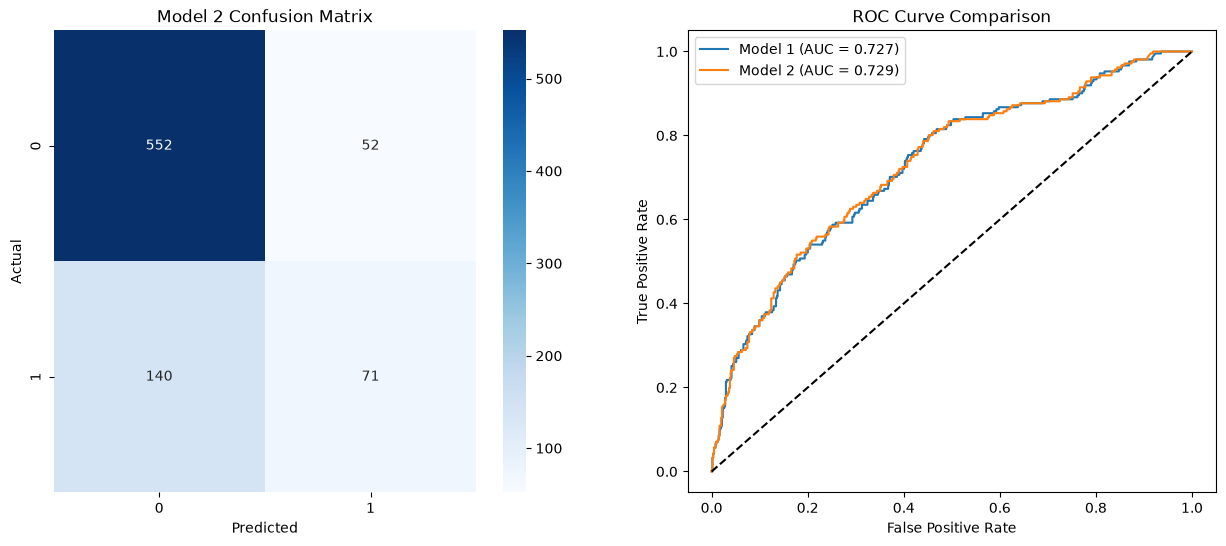

In [7]:
from sklearn.metrics import confusion_matrix, roc_curve

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Confusion Matrix Model 2
cm = confusion_matrix(y_array, pred_2)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Model 2 Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# ROC Curve Comparison
fpr1, tpr1, _ = roc_curve(y_array, prob_1)
fpr2, tpr2, _ = roc_curve(y_array, prob_2)
axes[1].plot(fpr1, tpr1, label=f'Model 1 (AUC = {metrics_1[4]:.3f})')
axes[1].plot(fpr2, tpr2, label=f'Model 2 (AUC = {metrics_2[4]:.3f})')
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_title('ROC Curve Comparison')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend()

plt.show()